# Vegetation change in the Braulio valley, 1953 → 2023

**Research question.** How did the alpine vegetation of the Braulio valley (Stelvio, Italian Alps) change between the 1953 survey (Giacomini & Pignatti) and the 2023 resurvey of the same plots, and which environmental variables explain the species composition?

The notebook has four steps:

1. **Data description**: plots, taxa, elevation range, most abundant taxa
2. **Environment**: what changed between 1953 and 2023 in the same plots
3. **Species change**: richness, species pool, winners and losers
4. **Explaining the species composition**: redundancy analysis (RDA)

*Kernel: R. Put the two `.xlsx` files in `data/` next to this notebook.*

## 0. Setup

In [1]:
needed <- c("tidyverse", "readxl", "vegan", "patchwork", "ggrepel", "knitr")
to_install <- needed[!needed %in% rownames(installed.packages())]
if (length(to_install)) install.packages(to_install, repos = "https://cloud.r-project.org")
invisible(lapply(needed, library, character.only = TRUE))

set.seed(42)
theme_set(theme_minimal(base_size = 12))
period_cols <- c("1953" = "#D95F02", "2023" = "#1B9E77")
options(repr.plot.width = 12, repr.plot.height = 6, repr.plot.res = 110)

# show tables as HTML in Jupyter
fmt_p <- function(p) format.pval(p, digits = 2, eps = 0.001)

show <- function(x, caption = NULL, digits = 2)
  IRdisplay::display_html(as.character(knitr::kable(x, format = "html", caption = caption, digits = digits)))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.4.4     ✔ tibble    3.2.1
✔ lubridate 1.9.3     ✔ tidyr     1.3.1
✔ purrr     1.0.2     


── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


Loading required package: permute



Loading required package: lattice



This is vegan 2.6-4



In [2]:
env_raw <- read_excel("data/Environmental_variables.xlsx", na = c("", "NA"))
sp_raw  <- read_excel("data/Species_data_final.xlsx",      na = c("", "NA"))

short_names <- c(
  "plot_id", "year", "elevation", "slope", "eastness", "northness", "log_spi",
  "morphology", "livestock_units", "solar_rad", "mat", "map", "summer_temp",
  "summer_prec", "shm", "liv_temp", "liv_light", "gdd5", "snow_days",
  "mineralogy", "liv_ph", "liv_nutrients", "liv_humus", "liv_moisture",
  "shannon", "evenness", "rc_trees", "rc_shrubs", "rc_dwarf_shrubs", "rc_herbs",
  "rc_graminoids", "rc_legumes", "rc_lichens", "rc_mosses",
  "p_competitive", "p_crs", "p_ruderal", "p_stress_tol",
  "pc1_thermal", "pc2_soil", "richness", "cover_total", "cover_vascular",
  "cover_lichens", "cover_mosses", "lat", "lon",
  "assoc_abbr", "association", "habitat")
stopifnot(ncol(env_raw) == length(short_names))

env <- env_raw %>%
  set_names(short_names) %>%
  mutate(plot_id = as.character(plot_id),
         base_id = str_remove(plot_id, "_23$"),        # same permanent plot in both years
         period  = factor(year, levels = c(1953, 2023)),
         assoc_abbr = recode(assoc_abbr, "SHa" = "Sha"),  # typo in the data
         across(c(morphology, mineralogy), as.factor))

comm <- sp_raw %>% mutate(plot_ID = as.character(plot_ID)) %>%
  column_to_rownames("plot_ID") %>% as.matrix()          # plots x taxa, cover in %

# keep the plots that are in both tables, in the same order
env_sp <- env %>% filter(plot_id %in% rownames(comm))
comm   <- comm[env_sp$plot_id, ]

# plots surveyed in both years (with species data)
paired_ids <- env_sp %>% count(base_id) %>% filter(n == 2) %>% pull(base_id)

In [3]:
# mosses and lichens: there is no column for this, so they are flagged by genus
nonvasc_genera <- c("Alectoria", "Anthelia", "Arctoa", "Barbilophozia", "Bartramia", "Brachythecium",
  "Bryoerythrophyllum", "Bryum", "Cetraria", "Cladonia", "Climacium", "Cynodontium", "Dicranum",
  "Drepanocladus", "Flavocetraria", "Hylocomium", "Hypnum", "Lescuraea", "Lobaria", "Nephromopsis",
  "Ochrolechia", "Oncophorus", "Paraleucobryum", "Peltigera", "Philonotis", "Plagiothecium",
  "Pleuroclada", "Polytrichastrum", "Polytrichum", "Ptychostomum", "Racomitrium", "Sanionia",
  "Sarmentypnum", "Scapania", "Solorina", "Stereocaulon", "Syntrichia", "Thamnolia", "Tortella",
  "Tortula", "Webera", "Weissia")
is_nonvasc <- str_detect(colnames(comm), paste0("^(", paste(nonvasc_genera, collapse = "|"), ")\\b"))
names(is_nonvasc) <- colnames(comm)

# Steps 3 and 4: use vascular plants only? (see the note in step 1 on mosses and lichens)
vascular_only <- TRUE
comm_an <- if (vascular_only) comm[, !is_nonvasc] else comm
A <- comm_an[paired_ids, ]                  # 1953, paired plots
B <- comm_an[paste0(paired_ids, "_23"), ]   # 2023, same plots

## 1. Data description

In [4]:
in_1953 <- colSums(comm[env_sp$period == "1953", ] > 0) > 0
in_2023 <- colSums(comm[env_sp$period == "2023", ] > 0) > 0

overview <- tibble(
  item = c("Plots in total (species table)", "Plots surveyed in both years",
           "Taxa in total", "  of which vascular plants", "  of which mosses / lichens",
           "Taxa found in only 1 plot", "Taxa found in >= 5 plots",
           "Elevation min [m]", "Elevation max [m]"),
  value = c(nrow(comm), length(paired_ids),
            ncol(comm), sum(!is_nonvasc), sum(is_nonvasc),
            sum(colSums(comm > 0) == 1), sum(colSums(comm > 0) >= 5),
            min(env_sp$elevation), max(env_sp$elevation)))
show(overview, "Overview of the data set", digits = 0)

env_sp %>% group_by(period) %>%
  summarise(plots = n(),
            taxa = sum(colSums(comm[plot_id, ] > 0) > 0),
            mosses_lichens = sum(colSums(comm[plot_id, is_nonvasc] > 0) > 0),
            elev_min = min(elevation), elev_max = max(elevation)) %>%
  show("Per survey year")

item,value
Plots in total (species table),83
Plots surveyed in both years,41
Taxa in total,373
of which vascular plants,313
of which mosses / lichens,60
Taxa found in only 1 plot,108
Taxa found in >= 5 plots,150
Elevation min [m],2005
Elevation max [m],2744


period,plots,taxa,mosses_lichens,elev_min,elev_max
1953,41,289,58,2005.2,2744.2
2023,42,280,20,2005.2,2744.2


Notes:
- Plot `17bis` has environmental data but no species data, so species analyses use 41 paired plots.
- **Mosses and lichens were not recorded the same way in both surveys**: 58 taxa in 1953 but only 20 in 2023, and in 2023 several are only identified to genus (e.g. *Polytrichum* sp.). Comparing them between years would show recording differences, not real change. Steps 3 and 4 therefore use **vascular plants only** (switch `vascular_only` in the setup to include them).

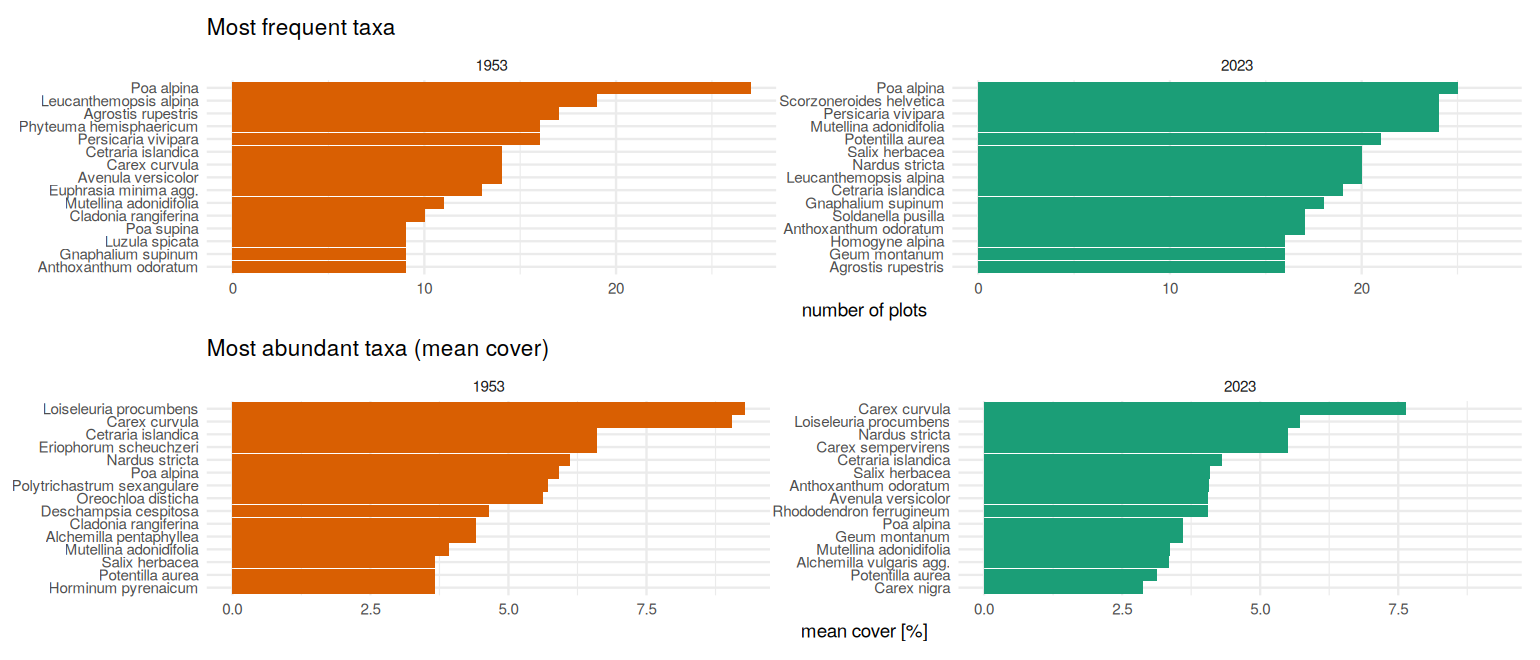

In [5]:
options(repr.plot.width = 14, repr.plot.height = 6)
top_n_taxa <- 15
top <- map_dfr(c("1953", "2023"), function(p) {
  m <- comm[env_sp$period == p, ]
  tibble(period = p, taxon = colnames(m),
         frequency = colSums(m > 0), mean_cover = colMeans(m))
})

p_freq <- top %>% group_by(period) %>% slice_max(frequency, n = top_n_taxa, with_ties = FALSE) %>%
  ggplot(aes(frequency, reorder(paste(taxon, period, sep = "__"), frequency), fill = period)) + geom_col() +
  facet_wrap(~ period, scales = "free_y") + scale_y_discrete(labels = ~ str_remove(.x, "__.*")) + scale_fill_manual(values = period_cols, guide = "none") +
  labs(x = "number of plots", y = NULL, title = "Most frequent taxa")
p_cov <- top %>% group_by(period) %>% slice_max(mean_cover, n = top_n_taxa, with_ties = FALSE) %>%
  ggplot(aes(mean_cover, reorder(paste(taxon, period, sep = "__"), mean_cover), fill = period)) + geom_col() +
  facet_wrap(~ period, scales = "free_y") + scale_y_discrete(labels = ~ str_remove(.x, "__.*")) + scale_fill_manual(values = period_cols, guide = "none") +
  labs(x = "mean cover [%]", y = NULL, title = "Most abundant taxa (mean cover)")
p_freq / p_cov

## 2. Environment: what changed between 1953 and 2023?

The topography (elevation, slope, aspect, mineralogy) is **the same in both years**, because the same plots were resurveyed. Only **climate** and **grazing** differ between the surveys, so this step compares those, plot by plot (paired Wilcoxon test).

The climate variables come from a downscaling model (ClimateEU). They are almost entirely determined by elevation and year, and are strongly correlated with each other (see the check below). One temperature variable and one precipitation variable are enough.

In [6]:
# how much of each climate variable is explained by elevation + year alone?
clim_all <- c("mat", "summer_temp", "gdd5", "snow_days", "summer_prec", "map")
map_dfr(clim_all, ~ tibble(variable = .x,
  r2_elev_year = summary(lm(reformulate(c("elevation", "period"), .x), data = env))$r.squared)) %>%
  show("R² of climate ~ elevation + year", digits = 3)

variable,r2_elev_year
mat,0.999
summer_temp,0.997
gdd5,0.982
snow_days,0.969
summer_prec,0.964
map,0.650


In [7]:
env_vars <- c("summer_temp" = "Mean summer temperature [°C]",
              "snow_days"   = "Snow cover days [n]",
              "gdd5"        = "Growing degree days > 5 °C",
              "summer_prec" = "Mean summer precipitation [mm]",
              "livestock_units" = "Livestock units")

env_paired <- env %>% filter(base_id %in% env$base_id[duplicated(env$base_id)]) %>%
  select(base_id, period, all_of(names(env_vars))) %>%
  pivot_longer(-c(base_id, period), names_to = "variable") %>%
  pivot_wider(names_from = period, values_from = value, names_prefix = "y")

env_paired %>% group_by(variable) %>%
  summarise(n_plots = n(), mean_1953 = mean(y1953), mean_2023 = mean(y2023),
            mean_change = mean(y2023 - y1953),
            p_value = fmt_p(wilcox.test(y2023, y1953, paired = TRUE, exact = FALSE)$p.value)) %>%
  mutate(variable = env_vars[variable]) %>%
  show("Paired comparison of the environment (same plots, 1953 vs 2023)", digits = 3)

variable,n_plots,mean_1953,mean_2023,mean_change,p_value
Growing degree days > 5 °C,42,252.333,359.167,106.834,<0.001
Livestock units,42,308.000,64.114,-243.886,<0.001
Snow cover days [n],42,278.063,247.548,-30.515,<0.001
Mean summer precipitation [mm],42,300.332,343.238,42.906,<0.001
Mean summer temperature [°C],42,5.724,6.926,1.202,<0.001


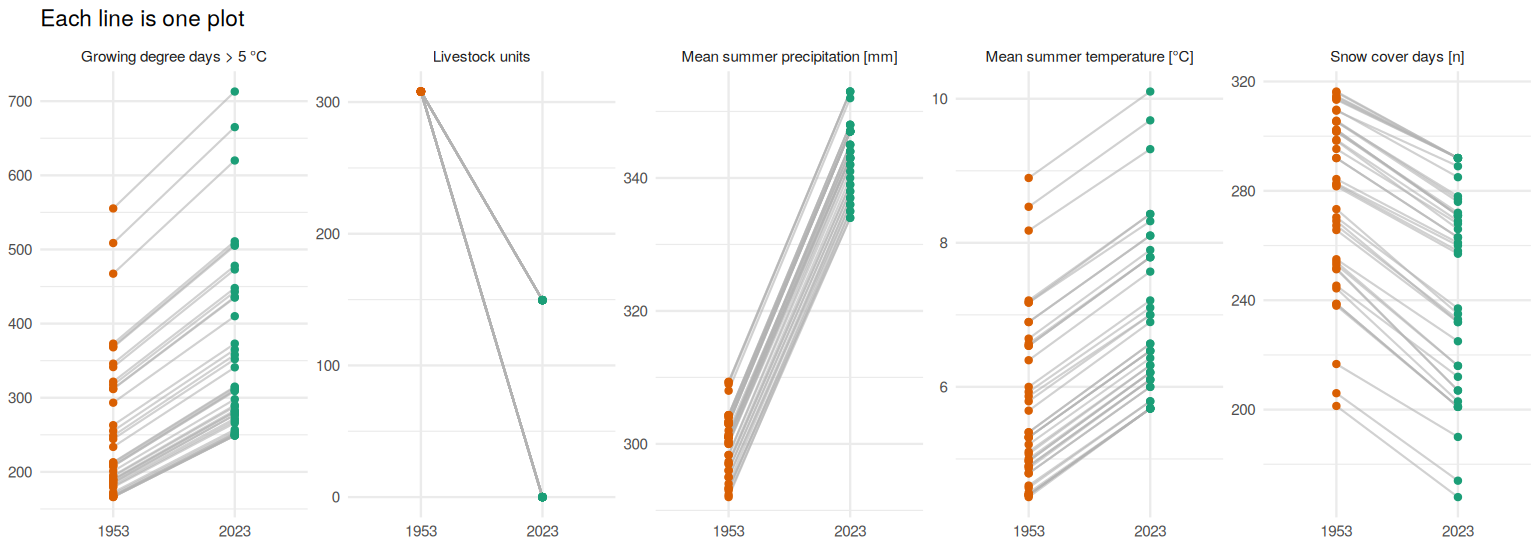

In [8]:
options(repr.plot.width = 14, repr.plot.height = 5)
env_paired %>% pivot_longer(c(y1953, y2023), names_to = "period", values_to = "value") %>%
  mutate(period = str_remove(period, "y"), variable = env_vars[variable]) %>%
  ggplot(aes(period, value, group = base_id)) +
  geom_line(colour = "grey70", alpha = .6) + geom_point(aes(colour = period)) +
  facet_wrap(~ variable, scales = "free_y", nrow = 1) +
  scale_colour_manual(values = period_cols, guide = "none") +
  labs(x = NULL, y = NULL, title = "Each line is one plot")

**Grazing:** in 1953 every plot has the same livestock value (308), so grazing cannot be separated from the year effect in 1953. It only varies between plots in 2023.

## 3. Species change (41 plots surveyed in both years, vascular plants)
### 3.1 Richness per plot and species pool

In [9]:
rich <- tibble(base_id = paired_ids,
               y1953 = rowSums(A > 0), y2023 = rowSums(B > 0))
w <- wilcox.test(rich$y2023, rich$y1953, paired = TRUE, exact = FALSE)

tibble(item = c("Mean taxa per plot 1953", "Mean taxa per plot 2023",
                "Mean change per plot", "Paired Wilcoxon p-value",
                "Taxa pool 1953 (all paired plots)", "Taxa pool 2023 (all paired plots)",
                "Taxa in both years", "Taxa only in 1953 (lost)", "Taxa only in 2023 (new)"),
       value = c(round(mean(rich$y1953), 1), round(mean(rich$y2023), 1),
                 round(mean(rich$y2023 - rich$y1953), 1), fmt_p(w$p.value),
                 sum(colSums(A > 0) > 0), sum(colSums(B > 0) > 0),
                 sum(colSums(A > 0) > 0 & colSums(B > 0) > 0),
                 sum(colSums(A > 0) > 0 & colSums(B > 0) == 0),
                 sum(colSums(A > 0) == 0 & colSums(B > 0) > 0))) %>%
  show("Richness and species pool")

item,value
Mean taxa per plot 1953,19.3
Mean taxa per plot 2023,28.2
Mean change per plot,8.9
Paired Wilcoxon p-value,<0.001
Taxa pool 1953 (all paired plots),231
Taxa pool 2023 (all paired plots),260
Taxa in both years,178
Taxa only in 1953 (lost),53
Taxa only in 2023 (new),82


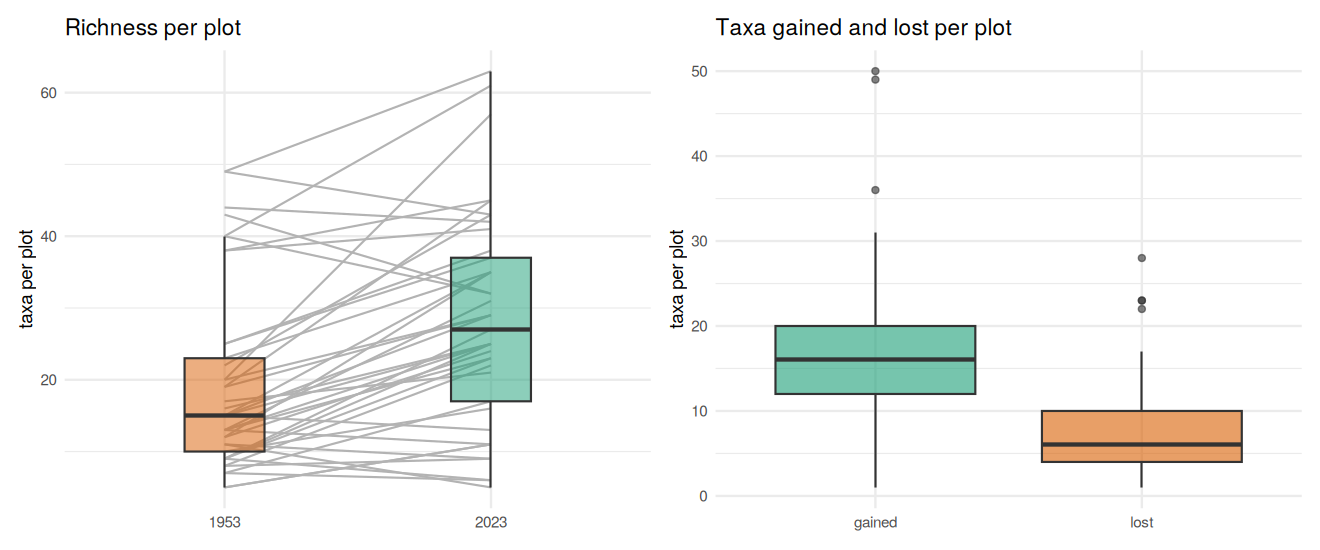

In [10]:
options(repr.plot.width = 12, repr.plot.height = 5)
p1 <- rich %>% pivot_longer(-base_id, names_to = "period", values_to = "taxa") %>%
  mutate(period = str_remove(period, "y")) %>%
  ggplot(aes(period, taxa)) +
  geom_line(aes(group = base_id), colour = "grey70") +
  geom_boxplot(aes(fill = period), alpha = .5, width = .3, outlier.shape = NA) +
  scale_fill_manual(values = period_cols, guide = "none") +
  labs(x = NULL, y = "taxa per plot", title = "Richness per plot")

turn <- tibble(base_id = paired_ids,
               lost = rowSums(A > 0 & B == 0), gained = rowSums(A == 0 & B > 0))
p2 <- turn %>% pivot_longer(-base_id) %>%
  ggplot(aes(name, value, fill = name)) + geom_boxplot(alpha = .6) +
  scale_fill_manual(values = c(gained = "#1B9E77", lost = "#D95F02"), guide = "none") +
  labs(x = NULL, y = "taxa per plot", title = "Taxa gained and lost per plot")
p1 + p2

### 3.2 Winners and losers

For each taxon: in how many plots was it lost (present 1953, absent 2023) or gained (absent 1953, present 2023)? An exact McNemar test (binomial test on these two counts) tells whether the change is larger than chance. p-values are corrected for multiple testing (Benjamini–Hochberg).

In [11]:
sp_change <- tibble(taxon = colnames(comm_an),
                    plots_1953 = colSums(A > 0), plots_2023 = colSums(B > 0),
                    lost = colSums(A > 0 & B == 0), gained = colSums(A == 0 & B > 0),
                    cover_1953 = colMeans(A), cover_2023 = colMeans(B)) %>%
  filter(plots_1953 + plots_2023 > 0) %>%
  mutate(change_plots = plots_2023 - plots_1953,
         change_cover = cover_2023 - cover_1953,
         p = map2_dbl(lost, gained, ~ if (.x + .y == 0) NA else binom.test(.x, .x + .y)$p.value),
         p_adj = p.adjust(p, "BH"))

sp_change %>% filter(p_adj < 0.05) %>% arrange(desc(change_plots)) %>%
  select(taxon, plots_1953, plots_2023, change_plots, cover_1953, cover_2023, p_adj) %>%
  show("Taxa with a significant change in occurrence (adjusted p < 0.05)", digits = 3)

taxon,plots_1953,plots_2023,change_plots,cover_1953,cover_2023,p_adj
Scorzoneroides helvetica,9,23,14,2.934,1.749,0.037
Potentilla aurea,8,21,13,3.663,3.198,0.037


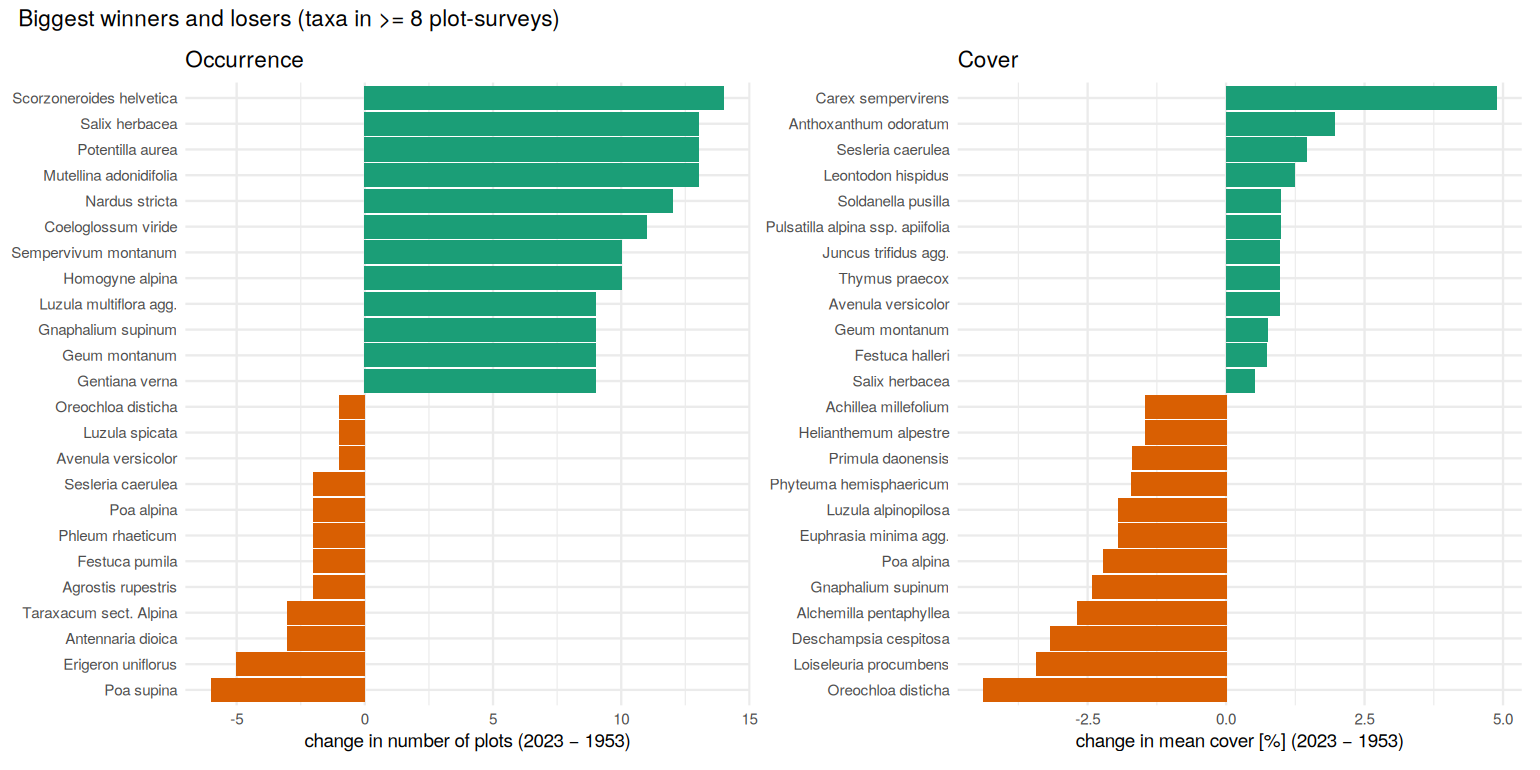

In [12]:
options(repr.plot.width = 14, repr.plot.height = 7)
n_show <- 12
common <- sp_change %>% filter(plots_1953 + plots_2023 >= 8)   # skip very rare taxa

p_occ <- common %>% arrange(change_plots) %>% { bind_rows(head(., n_show), tail(., n_show)) } %>%
  ggplot(aes(change_plots, reorder(taxon, change_plots), fill = change_plots > 0)) + geom_col() +
  scale_fill_manual(values = c("TRUE" = "#1B9E77", "FALSE" = "#D95F02"), guide = "none") +
  labs(x = "change in number of plots (2023 − 1953)", y = NULL, title = "Occurrence")
p_cov <- common %>% arrange(change_cover) %>% { bind_rows(head(., n_show), tail(., n_show)) } %>%
  ggplot(aes(change_cover, reorder(taxon, change_cover), fill = change_cover > 0)) + geom_col() +
  scale_fill_manual(values = c("TRUE" = "#1B9E77", "FALSE" = "#D95F02"), guide = "none") +
  labs(x = "change in mean cover [%] (2023 − 1953)", y = NULL, title = "Cover")
(p_occ + p_cov) + plot_annotation(title = "Biggest winners and losers (taxa in >= 8 plot-surveys)")

## 4. Explaining the species composition (RDA)

**Method.** A redundancy analysis (RDA) asks how much of the variation in species composition between plots can be explained by a set of environmental variables, and draws plots, species and variables in one diagram (triplot).

**Preparation.**
- Vascular plants only (see step 1), and only taxa found in **at least 5 plots** are kept (rare taxa add noise and little information).
- Cover is **Hellinger-transformed** (square root of relative cover in the plot), the standard choice for RDA on species data: it avoids treating shared absences as similarity.

**Explanatory variables.** Only variables measured independently of the vegetation:
- topography: elevation, slope, northness, mineralogy
- **year** (1953 / 2023)

Left out on purpose:
- **climate**: it is elevation + year (R² ≈ 1, see step 2), so it would duplicate them. The year effect *is* the climate + grazing change.
- **livestock**: in 1953 it equals the year, so it adds no separate information.
- **Landolt values, CSR, diversity, cover**: these are computed *from* the species, so using them to explain the species would be circular.

In [13]:
min_plots <- 5
Y   <- comm_an[, colSums(comm_an > 0) >= min_plots]
Y_h <- decostand(Y, "hellinger")
X   <- env_sp %>% select(elevation, slope, northness, mineralogy, period) %>% as.data.frame()
cat("Species matrix for the RDA:", nrow(Y), "plots x", ncol(Y), "taxa\n")

rda_full <- rda(Y_h ~ elevation + slope + northness + mineralogy + period, data = X)
cat("\nVariance inflation factors (should be < 5-10):\n"); print(round(vif.cca(rda_full), 2))

Species matrix for the RDA: 83 plots x 135 taxa



Variance inflation factors (should be < 5-10):


   elevation        slope    northness mineralogysi   period2023 
        1.04         1.06         1.19         1.20         1.00 


In [14]:
r2 <- RsquareAdj(rda_full)
cat("Explained variance: R² =", round(r2$r.squared, 3), "| adjusted R² =", round(r2$adj.r.squared, 3), "\n\n")

cat("Global test:\n"); print(anova(rda_full, permutations = 999))
cat("\nTest of each variable (given the others):\n")
print(anova(rda_full, by = "margin", permutations = 999))
cat("\nTest of the axes:\n"); print(anova(rda_full, by = "axis", permutations = 999))

Explained variance: R² = 0.211 | adjusted R² = 0.16 



Global test:


Permutation test for rda under reduced model
Permutation: free
Number of permutations: 999

Model: rda(formula = Y_h ~ elevation + slope + northness + mineralogy + period, data = X)
         Df Variance      F Pr(>F)    
Model     5  0.18895 4.1243  0.001 ***
Residual 77  0.70554                  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1



Test of each variable (given the others):


Permutation test for rda under reduced model
Marginal effects of terms
Permutation: free
Number of permutations: 999

Model: rda(formula = Y_h ~ elevation + slope + northness + mineralogy + period, data = X)
           Df Variance      F Pr(>F)    
elevation   1  0.04040 4.4091  0.001 ***
slope       1  0.03694 4.0315  0.001 ***
northness   1  0.04078 4.4506  0.001 ***
mineralogy  1  0.05588 6.0986  0.001 ***
period      1  0.01096 1.1962  0.188    
Residual   77  0.70554                  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1



Test of the axes:


Permutation test for rda under reduced model
Forward tests for axes
Permutation: free
Number of permutations: 999

Model: rda(formula = Y_h ~ elevation + slope + northness + mineralogy + period, data = X)
         Df Variance      F Pr(>F)    
RDA1      1  0.06144 6.7058  0.001 ***
RDA2      1  0.05620 6.1336  0.001 ***
RDA3      1  0.03754 4.0968  0.001 ***
RDA4      1  0.02583 2.8188  0.001 ***
RDA5      1  0.00794 0.8668  0.697    
Residual 77  0.70554                  
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


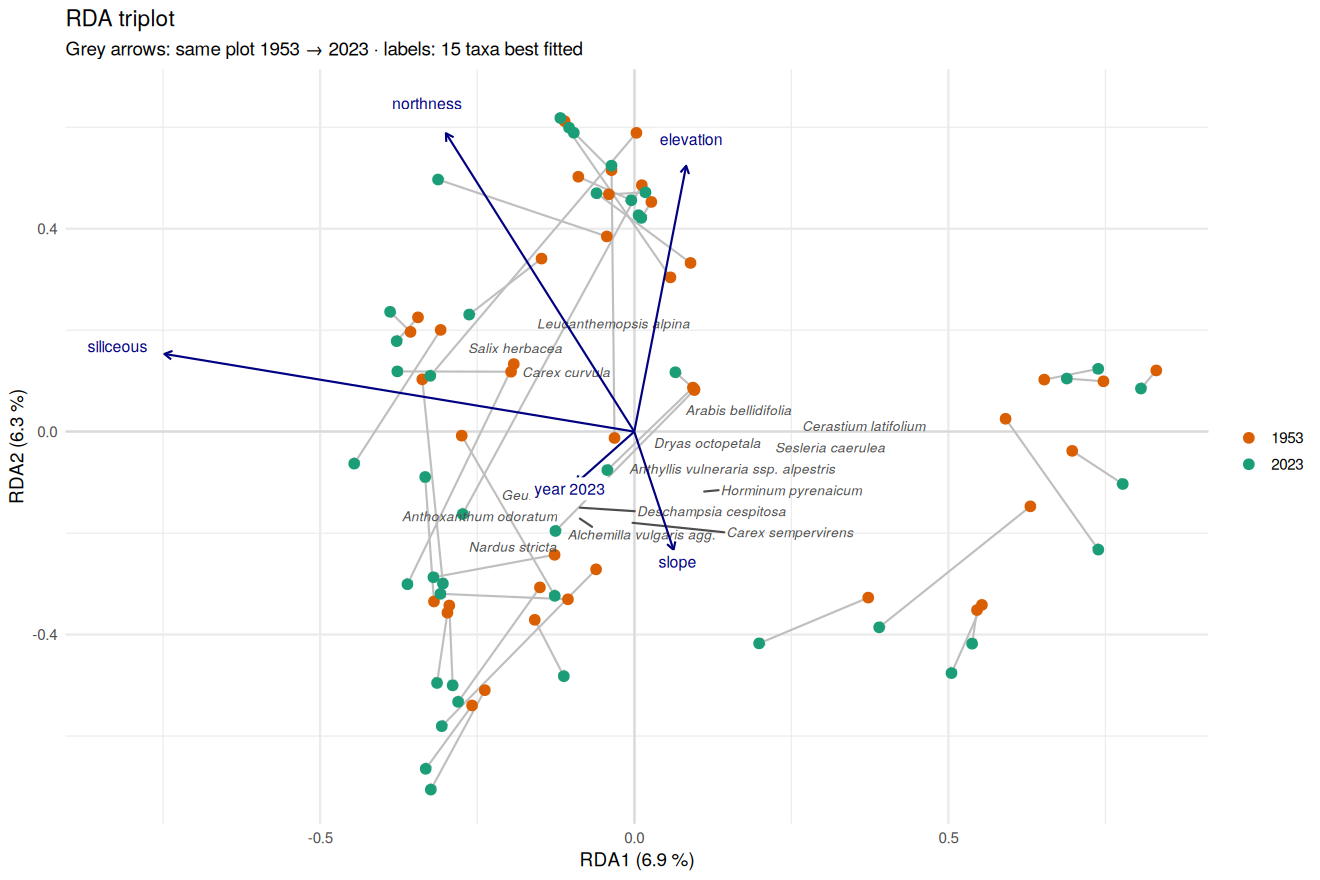

In [15]:
options(repr.plot.width = 12, repr.plot.height = 8)
pct <- round(100 * rda_full$CCA$eig[1:2] / rda_full$tot.chi, 1)

site_sc <- as_tibble(scores(rda_full, display = "sites", choices = 1:2, scaling = 2)) %>%
  bind_cols(env_sp %>% select(plot_id, base_id, period))
sp_sc  <- as.data.frame(scores(rda_full, display = "species", choices = 1:2, scaling = 2)) %>%
  rownames_to_column("taxon") %>% mutate(len = sqrt(RDA1^2 + RDA2^2)) %>% slice_max(len, n = 15)
bp     <- as.data.frame(scores(rda_full, display = "bp", choices = 1:2, scaling = 2)) %>%
  rownames_to_column("variable") %>%
  mutate(variable = recode(variable, mineralogysi = "siliceous", period2023 = "year 2023"))
k <- 0.9 * max(abs(site_sc$RDA1), abs(site_sc$RDA2)) / max(abs(bp$RDA1), abs(bp$RDA2))   # arrow scale

# arrows from each 1953 plot to its 2023 position
moves <- site_sc %>% filter(base_id %in% paired_ids) %>%
  select(base_id, period, RDA1, RDA2) %>%
  pivot_wider(names_from = period, values_from = c(RDA1, RDA2))

ggplot() +
  geom_hline(yintercept = 0, colour = "grey85") + geom_vline(xintercept = 0, colour = "grey85") +
  geom_segment(data = moves, aes(RDA1_1953, RDA2_1953, xend = RDA1_2023, yend = RDA2_2023),
               colour = "grey75", arrow = arrow(length = unit(1.5, "mm"))) +
  geom_point(data = site_sc, aes(RDA1, RDA2, colour = period), size = 2.5) +
  geom_text_repel(data = sp_sc, aes(RDA1, RDA2, label = taxon), size = 3, colour = "grey30",
                  fontface = "italic", max.overlaps = 20) +
  geom_segment(data = bp, aes(0, 0, xend = RDA1 * k, yend = RDA2 * k),
               colour = "navy", arrow = arrow(length = unit(2, "mm"))) +
  geom_label(data = bp, aes(RDA1 * k * 1.1, RDA2 * k * 1.1, label = variable),
             colour = "navy", size = 3.5, label.size = 0) +
  scale_colour_manual(values = period_cols) +
  labs(x = paste0("RDA1 (", pct[1], " %)"), y = paste0("RDA2 (", pct[2], " %)"), colour = NULL,
       title = "RDA triplot", subtitle = "Grey arrows: same plot 1953 → 2023 · labels: 15 taxa best fitted")

### 4.1 Did the composition change over time, within the same plots?

The RDA above compares all plots together, so most of the variation comes from the large differences *between* plots (elevation, substrate). To isolate the **change through time**, we run a *partial* RDA on the 41 paired plots. Plot identity is removed first (`Condition(base_id)`), and the permutations swap years only within each plot.

In [16]:
keep <- env_sp$base_id %in% paired_ids
X_p  <- env_sp[keep, ] %>% mutate(base_id = factor(base_id)) %>% as.data.frame()
rda_time <- rda(Y_h[keep, ] ~ period + Condition(base_id), data = X_p)

cat("Share of the within-plot variation explained by year:",
    round(rda_time$CCA$tot.chi / (rda_time$CCA$tot.chi + rda_time$CA$tot.chi), 3), "\n\n")
print(anova(rda_time, permutations = how(nperm = 999, blocks = X_p$base_id)))

Share of the within-plot variation explained by year: 0.044 



Permutation test for rda under reduced model
Blocks:  X_p$base_id 
Permutation: free
Number of permutations: 999

Model: rda(formula = Y_h[keep, ] ~ period + Condition(base_id), data = X_p)
         Df Variance      F Pr(>F)   
Model     1 0.011335 1.8224  0.002 **
Residual 40 0.248784                 
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1


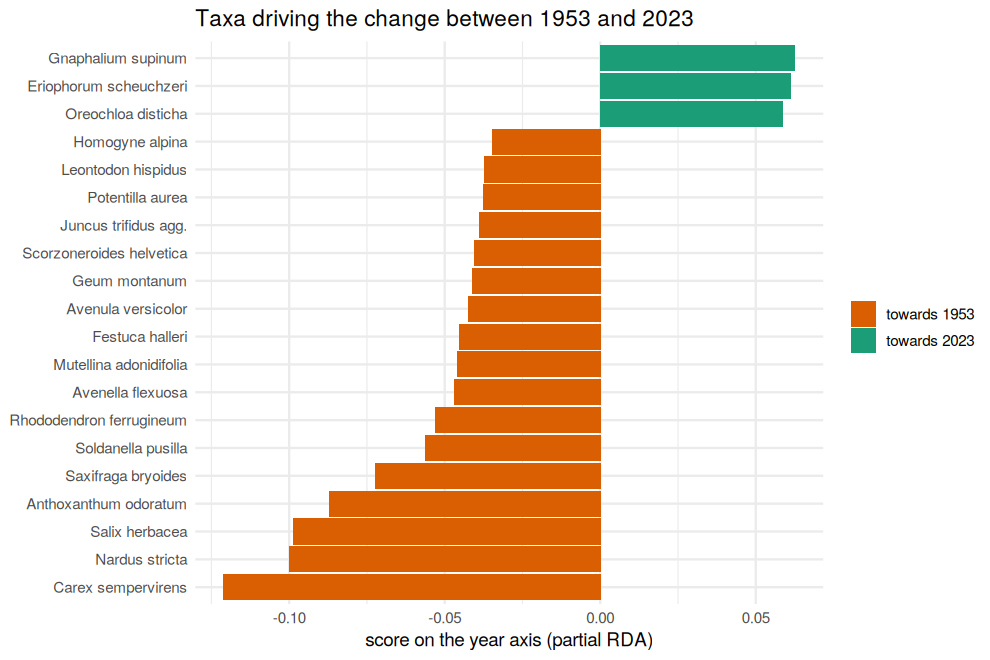

In [17]:
options(repr.plot.width = 9, repr.plot.height = 6)
# species most associated with the year axis: positive = more typical of 2023
sc_time <- as.data.frame(scores(rda_time, display = "species", choices = 1, scaling = 2)) %>%
  rownames_to_column("taxon") %>% rename(score = RDA1)
sc_time <- sc_time %>% slice_max(abs(score), n = 20)
ggplot(sc_time, aes(score, reorder(taxon, score), fill = score > 0)) + geom_col() +
  scale_fill_manual(values = c("TRUE" = "#1B9E77", "FALSE" = "#D95F02"),
                    labels = c("TRUE" = "towards 2023", "FALSE" = "towards 1953"), name = NULL) +
  labs(x = "score on the year axis (partial RDA)", y = NULL,
       title = "Taxa driving the change between 1953 and 2023")

## Summary

*Fill in from the outputs above:*
- **Data:** … plots, … taxa, elevation … – … m
- **Environment:** summer temperature +… °C, snow cover −… days, grazing reduced
- **Species:** richness per plot …, … taxa lost, … taxa new; main winners …, main losers …
- **RDA:** composition is mainly structured by …; year explains …% of within-plot change (p = …)